In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un compañero ha redactado el cuadro de prelaciones inmediatas del proyecto que se muestra a continuación. Antes de dibujar el grafo conviene revisarlo: sospechamos que contiene prelaciones redundantes (ya implicadas por otras) y al menos una errata que hace imposible ejecutar el proyecto.

In [4]:
pregunta_1 = "1. Compruebe si el cuadro es coherente. Si existe algún ciclo, identifíquelo e indique qué prelación debe eliminarse, suponiendo que la errata consiste en una actividad tardía anotada por error como predecesora de una temprana.  "
pregunta_2 = "2. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  "
pregunta_3 = "3. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  "
pregunta_4 = "4. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  "
pregunta_5 = "5. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Compruebe si el cuadro es coherente. Si existe algún ciclo, identifíquelo e indique qué prelación debe eliminarse, suponiendo que la errata consiste en una actividad tardía anotada por error como predecesora de una temprana.  

2. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  

3. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  

4. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  

5. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  

In [5]:
#| tbl-cap: "Cuadro de prelaciones tal y como lo recibimos"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('F'     , 'D'        ),
    ('G'     , 'E,F'      ),
    ('B'     , 'G'        ),
    ('I'     , 'A,C,E'    ),
    ('H'     , 'G'        ),
    ('E'     , 'C'        ),
    ('D'     , 'C'        ),
    ('A'     , '---'      ),
    ('C'     , 'A,B'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
F,D
G,"E,F"
B,G
I,"A,C,E"
H,G
E,C
D,C
A,---
C,"A,B"


El proyecto corresponde a la rehabilitación de una nave industrial para un taller; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'F': 'Levantamiento topográfico y mediciones',
    'G': 'Proyecto de ejecución y licencia',
    'B': 'Desmontaje de instalaciones antiguas',
    'I': 'Demolición de tabiquería interior',
    'H': 'Refuerzo de la estructura metálica',
    'E': 'Reparación de la cubierta',
    'D': 'Solera y canalizaciones',
    'A': 'Cerramientos y carpintería exterior',
    'C': 'Instalación eléctrica',
}, name='Descripción')
descripciones.to_frame()

,Descripción
F,Levantamiento topográfico y mediciones
G,Proyecto de ejecución y licencia
B,Desmontaje de instalaciones antiguas
I,Demolición de tabiquería interior
H,Refuerzo de la estructura metálica
E,Reparación de la cubierta
D,Solera y canalizaciones
A,Cerramientos y carpintería exterior
C,Instalación eléctrica


# Resolución

In [7]:
prelaciones_dadas = {act: set(p.strip() for p in fila.split(',') if p.strip() and p.strip() != '---')
                     for act, fila in datos_enunciado['predecessor'].items()}
G = nx.DiGraph()
G.add_nodes_from(prelaciones_dadas)
G.add_edges_from((p, a) for a, ps in prelaciones_dadas.items() for p in ps)

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Compruebe si el cuadro es coherente. Si existe algún ciclo, identifíquelo e indique qué prelación debe eliminarse, suponiendo que la errata consiste en una actividad tardía anotada por error como predecesora de una temprana.  

La librería detecta los ciclos al construir la tabla de prelaciones. Un ciclo significa que alguna actividad debería terminar antes de empezar ella misma, lo que hace el proyecto inejecutable.

In [9]:
try:
    PredecessorTable.from_dict_of_strings(datos_enunciado['predecessor'].to_dict())
    print('El cuadro no contiene ciclos.')
except ValueError as error:
    print(error)

La tabla de precedencias contiene un ciclo: C → D → F → G → B → C. Revisa las prelaciones: ninguna actividad puede preceder(se) a sí misma.


In [10]:
ciclos = list(nx.simple_cycles(G))
ciclos

[['B', 'C', 'E', 'G'], ['B', 'C', 'D', 'F', 'G']]

En el ciclo participa la prelación «G precede a B». Como G es, por el resto del cuadro, descendiente de B, esa anotación es la errata: eliminándola el cuadro vuelve a ser acíclico.

In [11]:
prelaciones_dadas['B'].discard('G')
G.remove_edge('G', 'B')
print('Ciclos restantes:', list(nx.simple_cycles(G)))

Ciclos restantes: []


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  

Una prelación «p precede a a» es redundante cuando p es antecesora de alguna otra predecesora inmediata de a: la relación ya está garantizada por transitividad. La reducción transitiva del grafo de prelaciones conserva exactamente las no redundantes.

In [13]:
reducido = nx.transitive_reduction(G)
redundantes = sorted(set(G.edges) - set(reducido.edges))
for p, a in redundantes:
    via = sorted(q for q in prelaciones_dadas[a] if q != p and p in nx.ancestors(G, q))
    print(f'{p} → {a} es redundante: {p} ya precede a {", ".join(via)}, que precede(n) a {a}')

A → I es redundante: A ya precede a C, E, que precede(n) a I
C → I es redundante: C ya precede a E, que precede(n) a I


In [14]:
#| tbl-cap: "Cuadro de prelaciones inmediatas mínimo"
#| label: tbl-prelacionesMinimas
prelaciones_minimas = {a: ','.join(sorted(reducido.predecessors(a))) or '---' for a in sorted(G.nodes)}
datos_proyecto = pd.DataFrame({'predecessor': pd.Series(prelaciones_minimas)})
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor
activity,
A,---
B,---
C,"A,B"
D,C
E,C
F,D
G,"E,F"
H,G
I,E


La librería hace esta misma depuración al construir la tabla de prelaciones, por lo que podemos usarla como comprobación:

In [15]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
pd.Series({a: ','.join(sorted(ps)) or '---' for a, ps in prelaciones.immediate_predecessor.items()}).to_frame('predecessor')

,predecessor
A,---
B,---
C,"A,B"
D,C
E,C
F,D
G,"E,F"
H,G
I,E


## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  

En el cuadro expandido cada fila indica las predecesoras inmediatas de una actividad y cada columna sus sucesoras inmediatas. Una fila vacía señala una actividad inicial; una columna vacía, una actividad final.

In [17]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I
activities,,,,,,,,,
A,,,,,,,,,
B,,,,,,,,,
C,True,True,,,,,,,
D,,,True,,,,,,
E,,,True,,,,,,
F,,,,True,,,,,
G,,,,,True,True,,,
H,,,,,,,True,,
I,,,,,True,,,,


In [18]:
print('Actividades iniciales:', ', '.join(sorted(prelaciones.start_activities)))
print('Actividades finales:  ', ', '.join(sorted(prelaciones.end_activities)))

Actividades iniciales: A, B
Actividades finales:   H, I


## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  

In [20]:
proyecto = prelaciones.create_project()

In [21]:
#| tbl-cap: "Cuadro de ancestros (prelaciones transitivas)"
#| label: tbl-ancestros
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,"A, B"
D,"A, B, C"
E,"A, B, C"
F,"A, B, C, D"
G,"A, B, C, D, E, F"
H,"A, B, C, D, E, F, G"
I,"A, B, C, E"


In [22]:
ancestros = proyecto.distant_predecessor()
for p, a in redundantes:
    print(f'{p} ∈ ancestros({a}): {p in ancestros[a]}')

A ∈ ancestros(I): True
C ∈ ancestros(I): True


## Apartado 5

In [23]:
display(Markdown(pregunta_5))

5. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  

Las actividades ficticias (discontinuas) del grafo transmiten precisamente las prelaciones que no pueden representarse compartiendo nodos. Siguiendo hacia atrás los arcos desde el final de cada actividad se recorren todos sus ancestros.

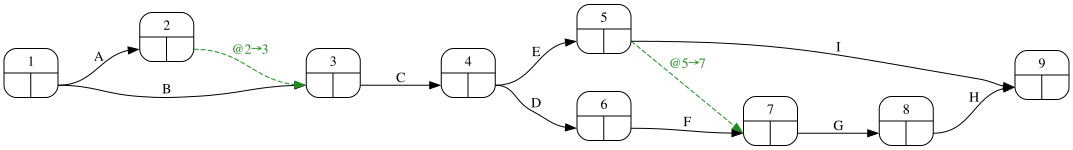

In [24]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)